# SVM + Réseau RBF - Rendu 3

- **Dataset original** : images 256×256. Les modèles reçoivent une **copie redimensionnée** en `TAILLE_IMAGE × TAILLE_IMAGE × 3` (8×8 = 192 variables ; 16×16 = 768).
- **Algorithmes** : apprentissage/prédiction en C++ via `ctypes` et `libPA_V2.dll` ; Python charge les images, exécute les expériences et produit les figures.
- **Trois classes** : stratégie *one-vs-rest* : 3 classifieurs binaires séparés, puis `argmax` des trois **scores continus** (`decision_svm`, `decision_rbf`).
- **Protocole** : échantillon initial équilibré **dans le train seulement** → train/validation → sélection hyperparamètres → réentraînement sur les images sélectionnées du train → évaluation sur test (une fois).


## 1. Configuration , modifie seulement ces valeurs pour commencer

Commencer avec **30 images d'entraînement par classe** (soit ~90 en tout), `TAILLE_IMAGE=8` et `MODE_RAPIDE=True`. Pour agrandir : `IMAGES_TRAIN_PAR_CLASSE = 100`, puis `200`, etc. `None` = totalité du train nettoyé, **coûteux pour le SVM**.

In [1]:
from pathlib import Path
import os, ctypes, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import sys
sys.path.insert(0, "../python")
import images_utils as iu

# À MODIFIER : dossier racine contenant train/<classe>/ + test/<classe>/
# ou <classe>/train/ + <classe>/test/
DATASET_DIR = Path("../dataset")
DLL_PATH = Path("../application/libPA_V2.dll")

TAILLE_IMAGE = 8                # 8 puis 16 ; les images 256x256 d'origine restent inchangées
IMAGES_TRAIN_PAR_CLASSE = 30   # 30 -> 100 -> 200 -> None (tout le train)
MODE_RAPIDE = True              # petite grille d'hyperparamètres pour valider le pipeline
NETTOYAGE_DOUBLONS = True       # dédoublonnage simple + miroirs (sans détection des rotations)
FRACTION_VALIDATION = 0.20
SEED = 42
RESULTS_DIR = Path('../results/SVM_RBF_dataset')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert DLL_PATH.exists(), f"DLL introuvable : {DLL_PATH}. Modifier DLL_PATH."
assert iu.organisation(str(DATASET_DIR)) is not None, (
    f"Dataset introuvable ou organisation incorrecte : {DATASET_DIR}. Modifier DATASET_DIR."
)
print('Dataset:', DATASET_DIR)
print('DLL:', DLL_PATH)
print('Taille:', TAILLE_IMAGE, 'x', TAILLE_IMAGE, '=>', 3*TAILLE_IMAGE**2, 'variables')

Dataset: dataset
DLL: libPA_V2.dll
Taille: 8 x 8 => 192 variables


## 2. Chargement, nettoyage et sous-échantillonnage

L'ordre alphabétique de `CLASSES` sert à coder les classes. Aucune image du **test** n'est utilisée pour choisir les hyperparamètres. Le nettoyage se fait à **32×32**, puis on recharge les mêmes indices à la taille `TAILLE_IMAGE`. Pour démarrer, le nettoyage par défaut `iu.nettoyer_train_test` peut prendre du temps sur plusieurs milliers d'images. Tu peux le désactiver pour un diagnostic technique, mais pas présenter ce test non nettoyé comme évaluation stricte.

In [2]:
CLASSES = iu.lister_classes_dataset(str(DATASET_DIR))
NB_CLASSES = len(CLASSES)
assert NB_CLASSES == 3, f"Trois classes attendues, trouvé : {CLASSES}"
print('Classes (ordre officiel):', CLASSES)

X32_tr, y_tr_all, chemins_tr, _ = iu.charger_dataset(str(DATASET_DIR), 'train', CLASSES, 32)
X32_te, y_te_all, chemins_te, _ = iu.charger_dataset(str(DATASET_DIR), 'test', CLASSES, 32)
print('Effectifs train bruts:', np.bincount(y_tr_all, minlength=NB_CLASSES))
print('Effectifs test bruts :', np.bincount(y_te_all, minlength=NB_CLASSES))

if NETTOYAGE_DOUBLONS:
    idx_tr_all, idx_te = iu.nettoyer_train_test(X32_tr, X32_te, miroirs=True)
else:
    idx_tr_all = np.arange(len(y_tr_all))
    idx_te = np.arange(len(y_te_all))

# Échantillonnage stratifié : on ne prélève QUE dans le train nettoyé.
rng = np.random.default_rng(SEED)
chosen = []
for c in range(NB_CLASSES):
    indices = idx_tr_all[y_tr_all[idx_tr_all] == c]
    if len(indices) < 3:
        raise ValueError(f'Pas assez d’images train propres pour {CLASSES[c]}: {len(indices)}')
    rng.shuffle(indices)
    chosen.extend(indices[:len(indices) if IMAGES_TRAIN_PAR_CLASSE is None
                          else min(IMAGES_TRAIN_PAR_CLASSE, len(indices))])
idx_tr = np.sort(np.asarray(chosen, dtype=int))

def charger_taille(t):
    if t == 32:
        return X32_tr, X32_te
    A, _, _, _ = iu.charger_dataset(str(DATASET_DIR), 'train', CLASSES, t)
    B, _, _, _ = iu.charger_dataset(str(DATASET_DIR), 'test', CLASSES, t)
    return A, B

img_train, img_test = charger_taille(TAILLE_IMAGE)
X_train = np.ascontiguousarray(iu.vers_vecteurs(img_train[idx_tr]), dtype=np.float64)
X_test = np.ascontiguousarray(iu.vers_vecteurs(img_test[idx_te]), dtype=np.float64)
y_train = y_tr_all[idx_tr]
y_test = y_te_all[idx_te]
Y_train_ovr = np.ascontiguousarray(iu.etiquettes_pm1(y_train, NB_CLASSES), dtype=np.float64)

# Validation stratifiée à partir du train SEULEMENT.
idx_fit, idx_val = iu.separer_validation(y_train, fraction=FRACTION_VALIDATION, graine=SEED)
assert len(idx_fit) > 0 and len(idx_val) > 0
assert set(idx_fit).isdisjoint(set(idx_val))
print('Train choisi:', X_train.shape, np.bincount(y_train, minlength=NB_CLASSES))
print('Fit/Val:', len(idx_fit), '/', len(idx_val))
print('Test propre:', X_test.shape, np.bincount(y_test, minlength=NB_CLASSES))
print('NB: copies tournées non recherchées dans ce nettoyage simplifié. Pour une comparaison MLP stricte, réutiliser ses indices stricts.')

del X32_tr, X32_te, img_train, img_test

Classes (ordre officiel): ['jasmin', 'jonquille', 'sunflower']
Effectifs train bruts: [1456  839  882]
Effectifs test bruts : [364 210 221]
Train choisi: (90, 192) [30 30 30]
Fit/Val: 72 / 18
Test propre: (792, 192) [363 208 221]
NB: copies tournées non recherchées dans ce nettoyage simplifié. Pour une comparaison MLP stricte, réutiliser ses indices stricts.


## 3. Interface C++ (`ctypes`) — sans sklearn et sans réentraîner à la prédiction

Les classes Python ci-dessous appellent **tes fonctions C++ existantes**. Les modèles sont détruits automatiquement à la fermeture. `status=0` signifie convergence, `status=1` signifie solution approchée ; les autres retours sont traités comme des erreurs. L'implémentation SVM doit aussi avoir la petite vérification de `work->solution` proposée dans la version sécurisée de `SVM.cpp`.

In [3]:
lib = ctypes.CDLL(str(DLL_PATH.resolve()))
dbl_p = ctypes.POINTER(ctypes.c_double)
vptr = ctypes.c_void_p
i32 = ctypes.c_int32
f64 = ctypes.c_double

def ptr(a):
    return a.ctypes.data_as(dbl_p)

def arr2(X):
    X = np.ascontiguousarray(X, dtype=np.float64)
    if X.ndim == 1: X = X.reshape(1, -1)
    if X.ndim != 2: raise ValueError('X doit être de forme (n, d)')
    return X

# ---- SVM ----
lib.create_svm_model.argtypes = [i32, f64, i32, i32]
lib.create_svm_model.restype = vptr
lib.train_svm_model.argtypes = [vptr, dbl_p, dbl_p, i32, i32, f64]
lib.train_svm_model.restype = i32
lib.decision_svm.argtypes = [vptr, dbl_p]
lib.decision_svm.restype = f64
lib.get_num_support_vectors.argtypes = [vptr]
lib.get_num_support_vectors.restype = i32
lib.destroy_svm_model.argtypes = [vptr]
lib.destroy_svm_model.restype = None

# ---- RBF network ----
lib.create_rbf_model.argtypes = [i32, i32, f64]
lib.create_rbf_model.restype = vptr
lib.train_rbf_model.argtypes = [vptr, dbl_p, dbl_p, i32, i32, f64, i32]
lib.train_rbf_model.restype = i32
lib.decision_rbf.argtypes = [vptr, dbl_p]
lib.decision_rbf.restype = f64
lib.get_num_rbf_centers.argtypes = [vptr]
lib.get_num_rbf_centers.restype = i32
lib.destroy_rbf_model.argtypes = [vptr]
lib.destroy_rbf_model.restype = None

class BinaryCppModel:
    def __init__(self, algo, n_features, **params):
        self.algo, self.d, self.params = algo, n_features, params
        if algo == 'SVM':
            self.h = lib.create_svm_model(n_features, float(params['gamma']),
                                          int(params['degree']), int(params['kernel']))
        elif algo == 'RBF':
            self.h = lib.create_rbf_model(n_features, int(params['K']), float(params['gamma']))
        else:
            raise ValueError(algo)
        if not self.h: raise RuntimeError(f'Échec création modèle {algo}')
        self.support_count = None

    def fit(self, X, y):
        X = arr2(X)
        y = np.ascontiguousarray(y, dtype=np.float64).reshape(-1)
        if len(X) != len(y) or X.shape[1] != self.d:
            raise ValueError('Dimensions de X/Y incompatibles')
        if not {-1.0, 1.0}.issubset(set(np.unique(y))):
            raise ValueError('Chaque SVM/RBF binaire doit voir des +1 ET -1')
        if self.algo == 'SVM':
            code = lib.train_svm_model(self.h, ptr(X), ptr(y), len(X), self.d,
                                       float(self.params['C']))
            if code not in (0, 1):
                raise RuntimeError(f'OSQP a échoué: statut C++={code}. Réduis la taille/ajuste C, gamma.')
            self.support_count = int(lib.get_num_support_vectors(self.h))
            if self.support_count == 0:
                raise RuntimeError('SVM sans vecteur support : solution inutilisable')
        else:
            code = lib.train_rbf_model(self.h, ptr(X), ptr(y), len(X), self.d,
                                       float(self.params['lam']), int(self.params.get('maxIterations', 80)))
            if code != 0:
                raise RuntimeError(f'RBF échec de résolution: statut={code}; essaie lambda=1e-3 ou moins de centres')
        return self

    def decision(self, X):
        X = arr2(X)
        if X.shape[1] != self.d: raise ValueError('Dimensions inattendues')
        fn = lib.decision_svm if self.algo == 'SVM' else lib.decision_rbf
        scores = np.array([fn(self.h, ptr(row)) for row in X], dtype=np.float64)
        if not np.isfinite(scores).all(): raise RuntimeError('Scores non finis, vérifier entraînement et paramètres')
        return scores

    def close(self):
        if getattr(self, 'h', None):
            (lib.destroy_svm_model if self.algo == 'SVM' else lib.destroy_rbf_model)(self.h)
            self.h = None
    def __del__(self):
        try: self.close()
        except Exception: pass

class MultiClasseCpp:
    def __init__(self, algo, **params):
        self.algo, self.params, self.models = algo, params, []
    def fit(self, X, y):
        self.close()
        X = arr2(X)
        y = np.asarray(y, dtype=int)
        self.n_classes = NB_CLASSES
        try:
            for c in range(self.n_classes):
                m = BinaryCppModel(self.algo, X.shape[1], **self.params)
                self.models.append(m)
                m.fit(X, np.where(y == c, 1.0, -1.0))
        except Exception:
            self.close()
            raise
        return self
    def scores(self, X):
        if len(self.models) != self.n_classes: raise RuntimeError('Modèle non entraîné')
        return np.column_stack([m.decision(X) for m in self.models])
    def predict(self, X):
        return np.argmax(self.scores(X), axis=1)
    @property
    def n_sv_total(self):
        return sum(m.support_count for m in self.models) if self.algo == 'SVM' else None
    def close(self):
        for m in self.models: m.close()
        self.models = []
    def __del__(self):
        try: self.close()
        except Exception: pass

print('Interfaces SVM / RBF chargées.')

Interfaces SVM / RBF chargées.


## 4. Contrôle rapide avant les grilles — une seule configuration par modèle

Ici, on vérifie que **le C++ entraîne vraiment** les modèles sur le dataset réel et que les trois scores donnent des classes. Ce n'est pas encore l'évaluation finale.

In [4]:
CONFIG_TEST_SVM = dict(kernel=0, C=1.0, gamma=0.01, degree=2)  # kernel 0=linéaire
CONFIG_TEST_RBF = dict(K=10, gamma=0.01, lam=1e-3, maxIterations=80)

for algo, cfg in [('SVM', CONFIG_TEST_SVM), ('RBF', CONFIG_TEST_RBF)]:
    m = MultiClasseCpp(algo, **cfg)
    t0 = time.perf_counter()
    try:
        m.fit(X_train[idx_fit], y_train[idx_fit])
        pred = m.predict(X_train[idx_val])
        print(algo, 'val_accuracy=', round(float(np.mean(pred == y_train[idx_val])), 4),
              'temps=', round(time.perf_counter()-t0, 2), 's',
              'vecteurs_supports=', m.n_sv_total)
    finally:
        m.close()

SVM val_accuracy= 0.6667 temps= 0.03 s vecteurs_supports= 113
RBF val_accuracy= 0.7222 temps= 0.03 s vecteurs_supports= None


## 5. Sélection des hyperparamètres sur VALIDATION

Grilles volontairement courtes quand `MODE_RAPIDE=True`. Pour une expérience de recherche plus large, passer `MODE_RAPIDE=False`, mais attention au temps d'entraînement des SVM. Les scores de **test** ne sont pas utilisés ici.

Attention pour les images : `gamma` dépend fortement du nombre de dimensions (`TAILLE_IMAGE`) et de l'échelle des pixels. Il faut donc le rechercher plutôt que supposer que `gamma=1` est optimal.

In [5]:
if MODE_RAPIDE:
    svm_grid = [
        dict(kernel=0, C=c, gamma=0.01, degree=2) for c in (0.1, 1.0, 10.0)
    ] + [
        dict(kernel=2, C=c, gamma=g, degree=2)
        for c in (1.0, 10.0) for g in (0.001, 0.01)
    ] + [dict(kernel=1, C=1.0, gamma=0.01, degree=2)]
    rbf_grid = [dict(K=k, gamma=g, lam=1e-3, maxIterations=80)
                for k in (5, 10, 20) for g in (0.001, 0.01)]
else:
    svm_grid = [dict(kernel=0, C=c, gamma=0.01, degree=2)
                for c in (0.1, 1.0, 10.0)] + [
                dict(kernel=2, C=c, gamma=g, degree=2)
                for c in (0.1, 1.0, 10.0) for g in (0.0001, 0.001, 0.01, 0.1)
    ] + [dict(kernel=1, C=c, gamma=0.01, degree=d)
         for c in (0.1, 1.0) for d in (2, 3)]
    rbf_grid = [dict(K=k, gamma=g, lam=lam, maxIterations=100)
                for k in (5, 10, 20, 40) for g in (0.0001, 0.001, 0.01, 0.1)
                for lam in (1e-3, 1e-2)]

# RBF refuse K>N : adapter automatiquement après sous-échantillonnage.
rbf_grid = [p for p in rbf_grid if p['K'] <= len(idx_fit)]

def essayer_grille(algo, grid):
    results = []
    for j, p in enumerate(grid, 1):
        t0 = time.perf_counter()
        m = MultiClasseCpp(algo, **p)
        try:
            m.fit(X_train[idx_fit], y_train[idx_fit])
            acc_tr = float(np.mean(m.predict(X_train[idx_fit]) == y_train[idx_fit]))
            acc_val = float(np.mean(m.predict(X_train[idx_val]) == y_train[idx_val]))
            record = dict(algo=algo, params=p, train_acc=acc_tr, val_acc=acc_val,
                          secondes=time.perf_counter()-t0, n_sv=m.n_sv_total, error=None)
            print(f'{algo} {j}/{len(grid)} : val={acc_val:.2%}, train={acc_tr:.2%} | {p}')
        except Exception as e:
            record = dict(algo=algo, params=p, train_acc=np.nan, val_acc=np.nan,
                          secondes=time.perf_counter()-t0, n_sv=None, error=str(e))
            print(f'ECHEC {algo} {j}/{len(grid)} : {p} -> {e}')
        finally:
            m.close()
        results.append(record)
    ok = [r for r in results if r['error'] is None]
    if not ok: raise RuntimeError(f'Aucune configuration {algo} n’a abouti')
    best = sorted(ok, key=lambda r: (-r['val_acc'], r['secondes']))[0]
    print(f'\nMeilleur {algo} : validation {best["val_acc"]:.2%}, paramètres {best["params"]}\n')
    return results, best

res_svm, best_svm = essayer_grille('SVM', svm_grid)
res_rbf, best_rbf = essayer_grille('RBF', rbf_grid)

SVM 1/8 : val=72.22%, train=97.22% | {'kernel': 0, 'C': 0.1, 'gamma': 0.01, 'degree': 2}
SVM 2/8 : val=66.67%, train=100.00% | {'kernel': 0, 'C': 1.0, 'gamma': 0.01, 'degree': 2}
SVM 3/8 : val=66.67%, train=100.00% | {'kernel': 0, 'C': 10.0, 'gamma': 0.01, 'degree': 2}
SVM 4/8 : val=55.56%, train=66.67% | {'kernel': 2, 'C': 1.0, 'gamma': 0.001, 'degree': 2}
SVM 5/8 : val=66.67%, train=88.89% | {'kernel': 2, 'C': 1.0, 'gamma': 0.01, 'degree': 2}
SVM 6/8 : val=77.78%, train=86.11% | {'kernel': 2, 'C': 10.0, 'gamma': 0.001, 'degree': 2}
SVM 7/8 : val=83.33%, train=100.00% | {'kernel': 2, 'C': 10.0, 'gamma': 0.01, 'degree': 2}
SVM 8/8 : val=66.67%, train=100.00% | {'kernel': 1, 'C': 1.0, 'gamma': 0.01, 'degree': 2}

Meilleur SVM : validation 83.33%, paramètres {'kernel': 2, 'C': 10.0, 'gamma': 0.01, 'degree': 2}

RBF 1/6 : val=72.22%, train=63.89% | {'K': 5, 'gamma': 0.001, 'lam': 0.001, 'maxIterations': 80}
RBF 2/6 : val=66.67%, train=65.28% | {'K': 5, 'gamma': 0.01, 'lam': 0.001, 'maxIte

## 6. Figures des expérimentations — comparaison des noyaux, C, gamma, K

Les points montrent des **accuracies de validation** : on évite d'utiliser le jeu de test pour choisir les paramètres.

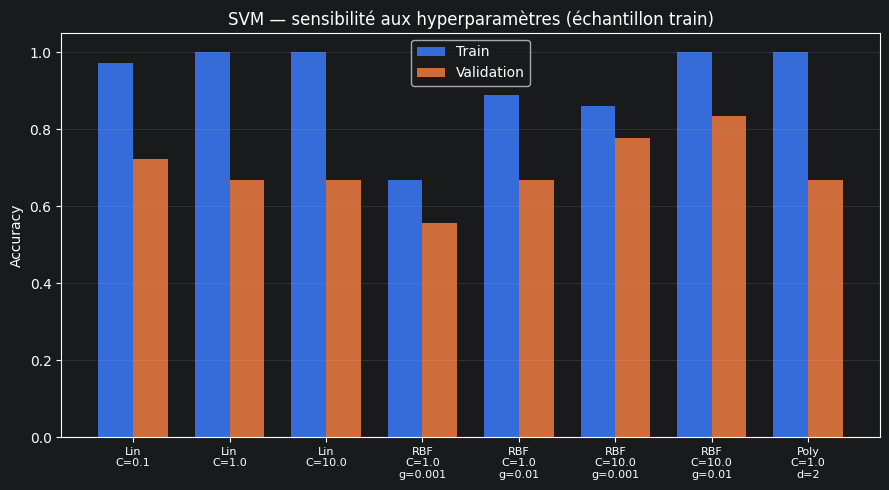

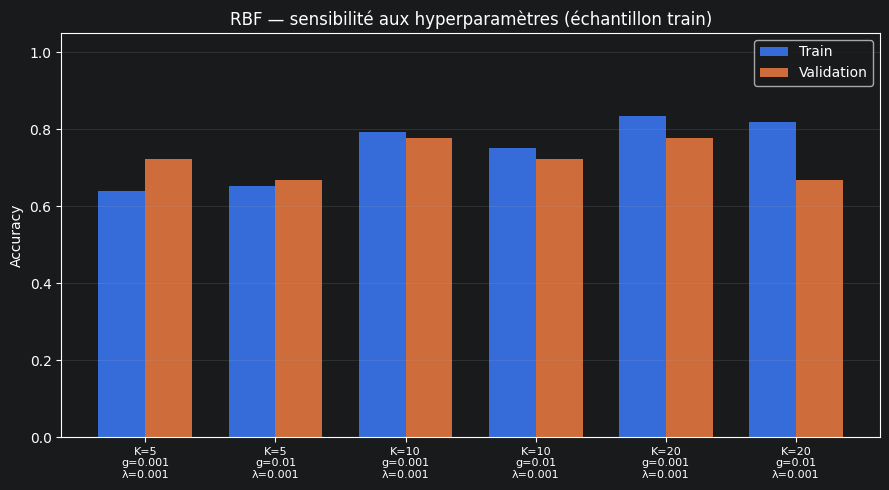

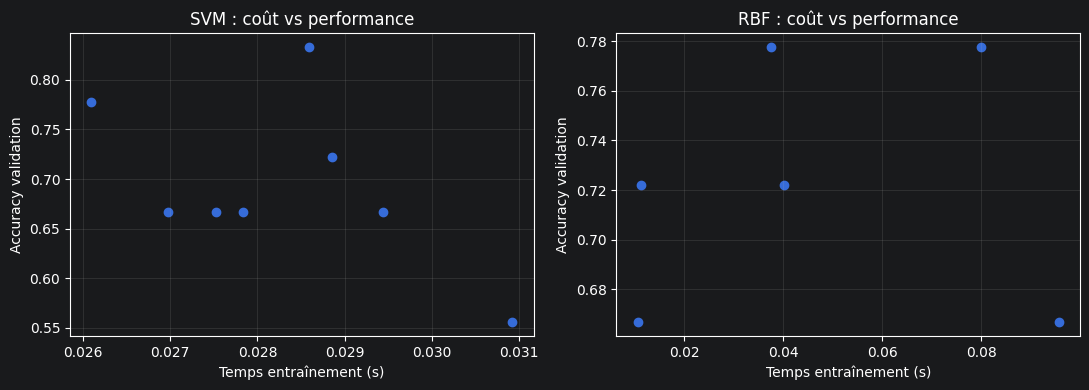

In [6]:
def tracer_scores(resultats, nom):
    valid = [r for r in resultats if r['error'] is None]
    labels = []
    for r in valid:
        p = r['params']
        if nom == 'SVM':
            k = {0: 'Lin', 1: 'Poly', 2: 'RBF'}[p['kernel']]
            labels.append(f'{k}\nC={p["C"]}\ng={p["gamma"]}' if p['kernel']==2 else
                          f'{k}\nC={p["C"]}' + (f'\nd={p["degree"]}' if p['kernel']==1 else ''))
        else:
            labels.append(f'K={p["K"]}\ng={p["gamma"]}\nλ={p["lam"]}')
    fig, ax = plt.subplots(figsize=(max(9, len(labels)*0.9), 5))
    ix = np.arange(len(valid))
    ax.bar(ix-0.18, [r['train_acc'] for r in valid], 0.36, label='Train')
    ax.bar(ix+0.18, [r['val_acc'] for r in valid], 0.36, label='Validation')
    ax.set_xticks(ix, labels, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Accuracy')
    ax.set_title(f'{nom} — sensibilité aux hyperparamètres (échantillon train)')
    ax.legend(); ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'validation_{nom.lower()}.png', dpi=150)
    plt.show()

tracer_scores(res_svm, 'SVM')
tracer_scores(res_rbf, 'RBF')

fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, results, label in zip(axes, (res_svm, res_rbf), ('SVM', 'RBF')):
    ok = [r for r in results if r['error'] is None]
    ax.scatter([r['secondes'] for r in ok], [r['val_acc'] for r in ok])
    ax.set_xlabel('Temps entraînement (s)'); ax.set_ylabel('Accuracy validation')
    ax.set_title(f'{label} : coût vs performance'); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(RESULTS_DIR / 'temps_vs_validation.png', dpi=150); plt.show()

## 7. Modèles finaux — réentraînement sur toutes les images **retenues du train**, puis test

Après sélection via la validation, on réentraîne avec l'ensemble `X_train` sélectionné. Le test est ensuite évalué sans aucun ajustement supplémentaire. Pour une évaluation finale sur tout le train nettoyé, remettre `IMAGES_TRAIN_PAR_CLASSE=None` et relancer **depuis le début** ; ce sera très coûteux en SVM avec OSQP. Ne pas choisir les hyperparamètres en regardant le score test.

In [7]:
final_svm = MultiClasseCpp('SVM', **best_svm['params'])
final_rbf = MultiClasseCpp('RBF', **best_rbf['params'])

try:
    t0=time.perf_counter(); final_svm.fit(X_train, y_train); temps_final_svm=time.perf_counter()-t0
    t0=time.perf_counter(); final_rbf.fit(X_train, y_train); temps_final_rbf=time.perf_counter()-t0
    pred_svm = final_svm.predict(X_test)
    pred_rbf = final_rbf.predict(X_test)
    print('SVM TEST :', f'{np.mean(pred_svm==y_test):.2%}',
          '| entraînement:', round(temps_final_svm,2),'s', '| SV total:', final_svm.n_sv_total)
    print('RBF TEST :', f'{np.mean(pred_rbf==y_test):.2%}',
          '| entraînement:', round(temps_final_rbf,2),'s')
except Exception:
    final_svm.close(); final_rbf.close()
    raise

SVM TEST : 75.88% | entraînement: 0.03 s | SV total: 175
RBF TEST : 73.74% | entraînement: 0.04 s


## 8. Matrices de confusion, précision/rappel/F1 et erreurs sur images

Aucune bibliothèque `sklearn` requise : les métriques sont calculées directement. Chaque ligne d'une matrice = classe réelle ; chaque colonne = classe prédite.

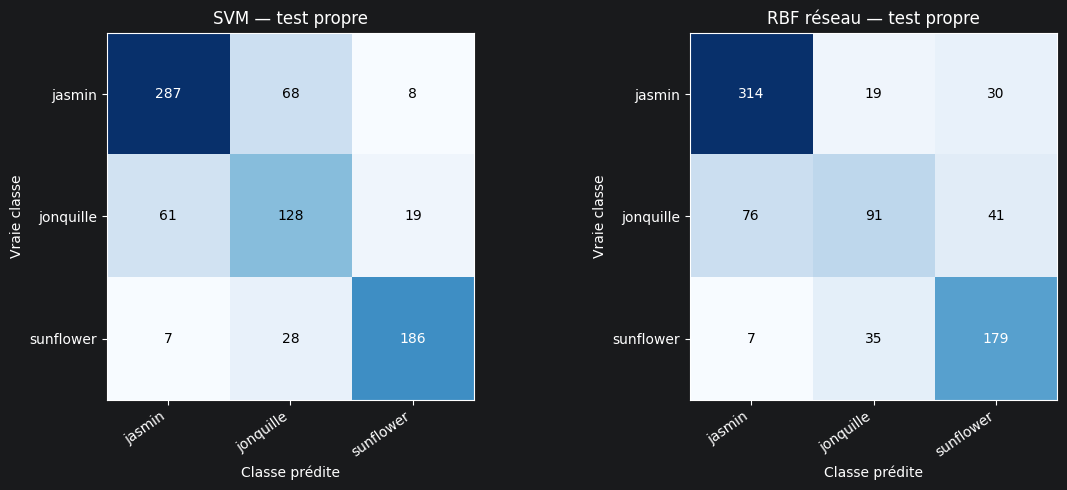


SVM: accuracy=75.88%  macro-F1=74.97%
  jasmin          précision=80.85% rappel=79.06% F1=79.94%
  jonquille       précision=57.14% rappel=61.54% F1=59.26%
  sunflower       précision=87.32% rappel=84.16% F1=85.71%

RBF: accuracy=73.74%  macro-F1=70.07%
  jasmin          précision=79.09% rappel=86.50% F1=82.63%
  jonquille       précision=62.76% rappel=43.75% F1=51.56%
  sunflower       précision=71.60% rappel=81.00% F1=76.01%


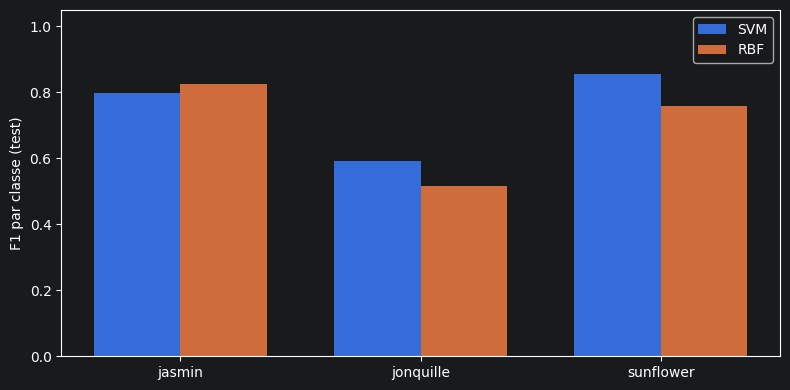

In [8]:
def matrice_confusion(y_vrai, y_pred, k):
    M = np.zeros((k,k), dtype=int)
    for a,b in zip(y_vrai,y_pred): M[int(a),int(b)] += 1
    return M

def metriques(M):
    tp = np.diag(M).astype(float)
    precision = np.divide(tp, M.sum(0), out=np.zeros(len(M)), where=M.sum(0)!=0)
    recall = np.divide(tp, M.sum(1), out=np.zeros(len(M)), where=M.sum(1)!=0)
    f1 = np.divide(2*precision*recall, precision+recall,
                   out=np.zeros(len(M)), where=(precision+recall)!=0)
    return dict(accuracy=float(tp.sum()/M.sum()), macro_f1=float(f1.mean()),
                precision=precision, recall=recall, f1=f1)

def dessiner_confusion(ax,M,titre):
    ax.imshow(M,cmap='Blues')
    ax.set_xticks(range(NB_CLASSES),CLASSES,rotation=35,ha='right')
    ax.set_yticks(range(NB_CLASSES),CLASSES)
    ax.set_xlabel('Classe prédite'); ax.set_ylabel('Vraie classe'); ax.set_title(titre)
    for i in range(NB_CLASSES):
        for j in range(NB_CLASSES):
            ax.text(j,i,str(M[i,j]),ha='center',va='center',
                    color='white' if M[i,j]>M.max()/2 else 'black')

M_svm = matrice_confusion(y_test,pred_svm,NB_CLASSES)
M_rbf = matrice_confusion(y_test,pred_rbf,NB_CLASSES)
perf_svm, perf_rbf = metriques(M_svm),metriques(M_rbf)
fig,ax=plt.subplots(1,2,figsize=(12,5))
dessiner_confusion(ax[0],M_svm,'SVM — test propre')
dessiner_confusion(ax[1],M_rbf,'RBF réseau — test propre')
fig.tight_layout(); fig.savefig(RESULTS_DIR/'matrices_confusion.png',dpi=150); plt.show()

for nom, perf in [('SVM',perf_svm),('RBF',perf_rbf)]:
    print(f'\n{nom}: accuracy={perf["accuracy"]:.2%}  macro-F1={perf["macro_f1"]:.2%}')
    for i,c in enumerate(CLASSES):
        print(f'  {c:15} précision={perf["precision"][i]:.2%} rappel={perf["recall"][i]:.2%} F1={perf["f1"][i]:.2%}')

fig,ax=plt.subplots(figsize=(8,4))
ix=np.arange(NB_CLASSES)
ax.bar(ix-.18,perf_svm['f1'],.36,label='SVM')
ax.bar(ix+.18,perf_rbf['f1'],.36,label='RBF')
ax.set_xticks(ix,CLASSES); ax.set_ylim(0,1.05)
ax.set_ylabel('F1 par classe (test)'); ax.legend(); fig.tight_layout()
fig.savefig(RESULTS_DIR/'f1_par_classe.png',dpi=150); plt.show()

SVM : 191 erreurs / 792 images test


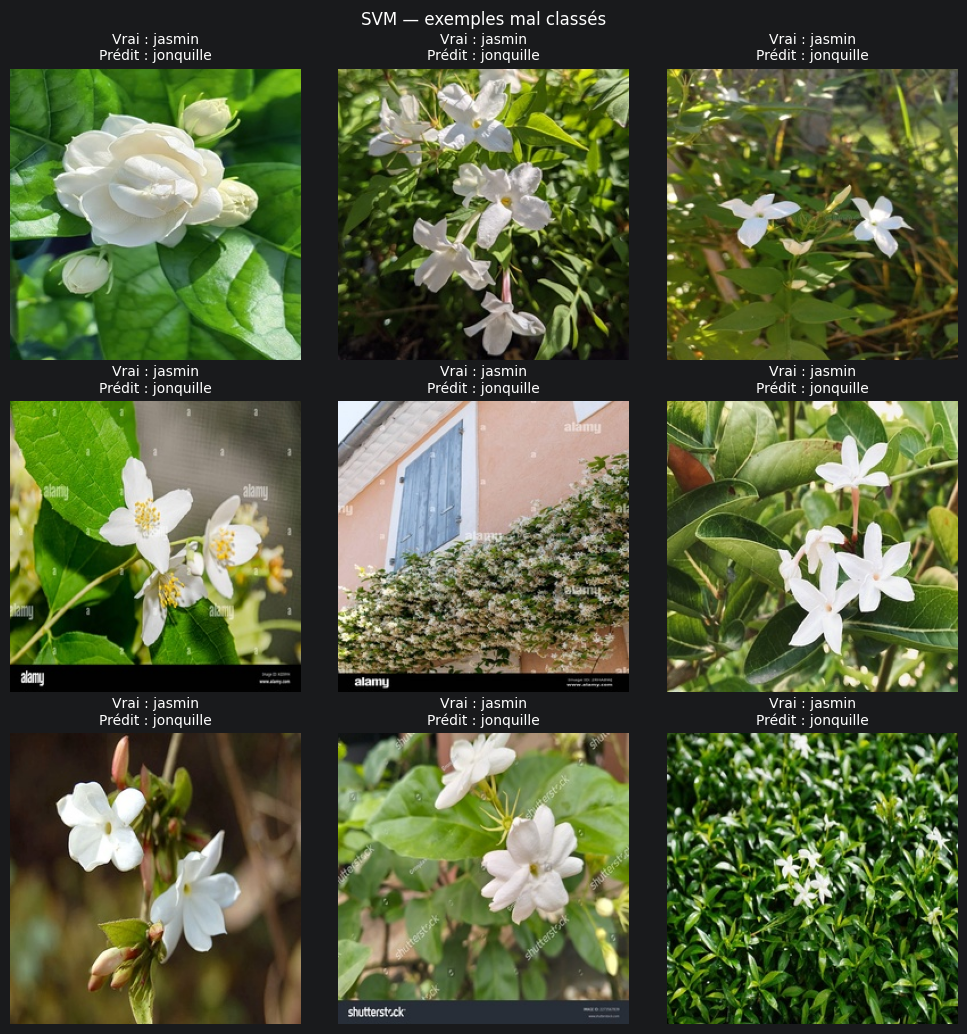

RBF : 208 erreurs / 792 images test


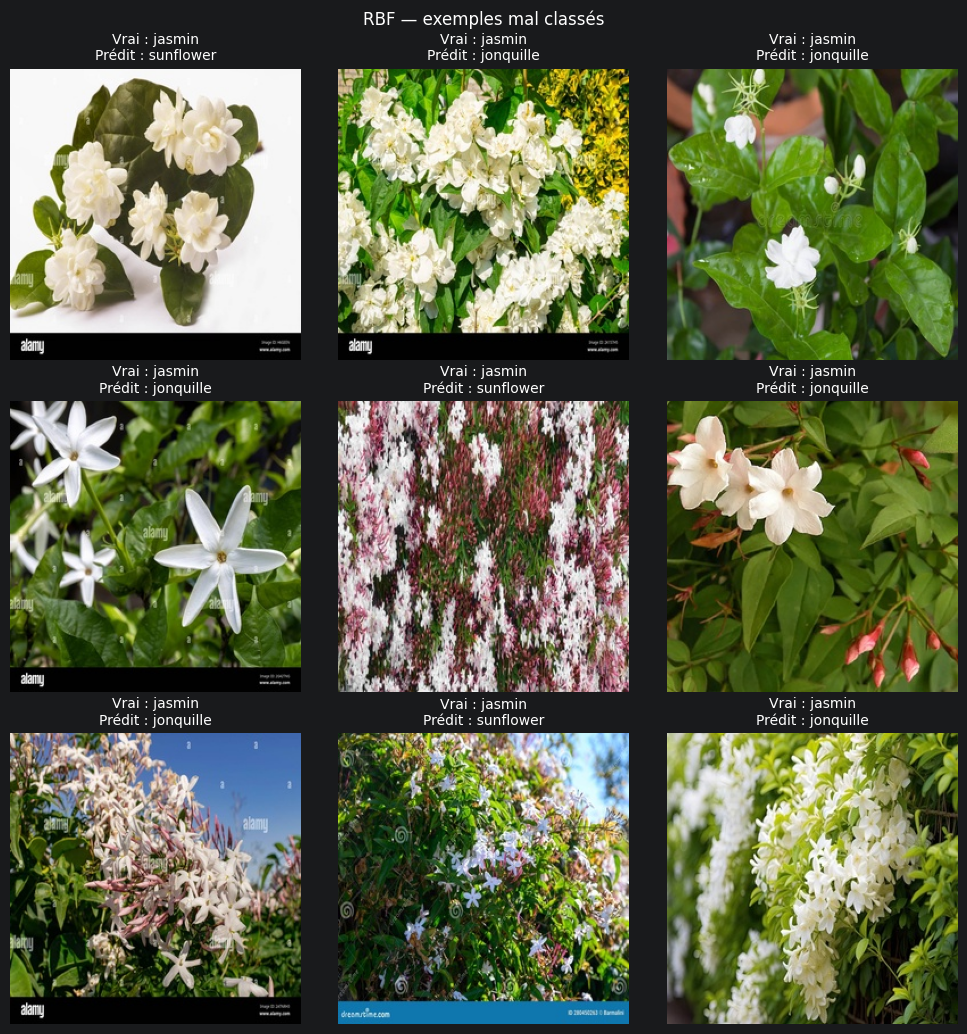

In [9]:
def montrer_erreurs(pred, nom, nb=9):
    incorrects=np.where(pred!=y_test)[0]
    print(f'{nom} : {len(incorrects)} erreurs / {len(y_test)} images test')
    if not len(incorrects): return
    selection=incorrects[:nb]
    colonnes=3; lignes=int(np.ceil(len(selection)/colonnes))
    fig,axes=plt.subplots(lignes,colonnes,figsize=(10,3.5*lignes),squeeze=False)
    for a in axes.flat: a.axis('off')
    for ax,i in zip(axes.flat,selection):
        im=Image.open(chemins_te[idx_te[i]]).convert('RGB')
        ax.imshow(im); ax.set_title(f'Vrai : {CLASSES[y_test[i]]}\nPrédit : {CLASSES[pred[i]]}',fontsize=10)
    fig.suptitle(f'{nom} — exemples mal classés')
    fig.tight_layout(); fig.savefig(RESULTS_DIR/f'erreurs_{nom.lower()}.png',dpi=150)
    plt.show()

montrer_erreurs(pred_svm,'SVM')
montrer_erreurs(pred_rbf,'RBF')

## 9. Tableau récapitulatif et export des résultats

Tous les scores affichés ci-dessous proviennent du **même test sélectionné**. Si `IMAGES_TRAIN_PAR_CLASSE` n'est pas `None`, il faut l'indiquer clairement dans ton rapport : **c'est une expérience sur sous-échantillon**, pas un modèle entraîné sur les ~2600 images.

In [10]:
import csv, json
rows=[
    dict(model='SVM',n_train=len(X_train),n_test=len(X_test),taille=TAILLE_IMAGE,
         accuracy=perf_svm['accuracy'],macro_f1=perf_svm['macro_f1'],
         train_seconds=temps_final_svm, params=str(best_svm['params']),sv=final_svm.n_sv_total),
    dict(model='RBF_network',n_train=len(X_train),n_test=len(X_test),taille=TAILLE_IMAGE,
         accuracy=perf_rbf['accuracy'],macro_f1=perf_rbf['macro_f1'],
         train_seconds=temps_final_rbf,params=str(best_rbf['params']),sv=''),
]
for row in rows: print(row)
with open(RESULTS_DIR/'resultats.csv','w',newline='',encoding='utf-8-sig') as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
with open(RESULTS_DIR/'configuration.json','w',encoding='utf-8') as f:
    json.dump(dict(classes=CLASSES,taille=TAILLE_IMAGE,n_train=len(X_train),n_test=len(X_test),
                   train_par_classe=IMAGES_TRAIN_PAR_CLASSE,nettoyage_doublons=NETTOYAGE_DOUBLONS,
                   best_svm=best_svm['params'],best_rbf=best_rbf['params']),f,indent=2,ensure_ascii=False)
print('Figures et CSV enregistrés dans',RESULTS_DIR.resolve())

{'model': 'SVM', 'n_train': 90, 'n_test': 792, 'taille': 8, 'accuracy': 0.7588383838383839, 'macro_f1': 0.7497261155571278, 'train_seconds': 0.02682259999892267, 'params': "{'kernel': 2, 'C': 10.0, 'gamma': 0.01, 'degree': 2}", 'sv': 175}
{'model': 'RBF_network', 'n_train': 90, 'n_test': 792, 'taille': 8, 'accuracy': 0.7373737373737373, 'macro_f1': 0.7006604839025382, 'train_seconds': 0.043012500000259024, 'params': "{'K': 10, 'gamma': 0.001, 'lam': 0.001, 'maxIterations': 80}", 'sv': ''}
Figures et CSV enregistrés dans C:\Users\Aya Bouchair\Downloads\PycharmProjects\PA2026\results_svm_rbf_reel


## 10. Ressources et suites

- **Pour les tests rapides** : 30 images/classe, 8×8, grille courte.
- **Pour les premiers résultats comparatifs** : 100 images/classe, puis 200/classe ; conserver la séparation validation/test.
- **Pour le dataset complet** : le RBF est généralement plus abordable ici ; avec ton SVM+OSQP, le problème dual comporte autant de variables que d'images et une matrice en O(N²), ce qui peut être lent et gourmand. Mesurer le temps avant de lancer ~2600 images × 3 SVM.
- **Comparaison équitable MLP** : utiliser exactement la même sélection nettoyée et les mêmes images de test. Le pipeline MLP de ta collègue applique aussi une détection plus coûteuse de copies tournées, que ce notebook ne reproduit pas automatiquement.
- **Streamlit** : l'étape suivante sera d'ajouter une sauvegarde explicite des vecteurs supports / coefficients / biais SVM et des centres / poids RBF. Tes C++ exposent les accesseurs nécessaires ; pas besoin de retoucher le fonctionnement du MLP.

À la fin de la session, libérer les modèles :

In [11]:
# À exécuter APRÈS avoir fini toutes les prédictions / analyses.
final_svm.close()
final_rbf.close()
print('Mémoire C++ libérée.')

Mémoire C++ libérée.
